In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import adabmDCA as dca
import RNA
import torch
import os

from concurrent.futures import ProcessPoolExecutor
from functools import partial

# use latex and font size 14
plt.rc('text', usetex=True)
plt.rc('font', size=14)
sns.set_style("whitegrid")

tokens = "ACGU-"
dot_bracket_with_pk = "...(((((((..((....)).)))))))...((((((....((((((...((...((((((....))))))..))...))))))(((...(.((((((....)))))).)..)))...[.[[[[[...))))))((((...(((....)))..))))......]]]]]]..((.(((((....))))).....)).."

In [2]:
def compute_bpp_matrix(sequence):
    """
    Compute the base-pairing probability (bpp) matrix via ViennaRNA.

    Parameters
    ----------
    sequence : str
        RNA sequence (T già convertiti in U se presenti gap).

    Returns
    -------
    bpp : np.ndarray, shape (L, L)
        Matrice simmetrica delle probabilità di appaiamento (L = len(sequence)).
    """
    fc = RNA.fold_compound(sequence)
    propensity, ensemble_energy = fc.pf()
    basepair_probs = fc.bpp()  # nested list, 1-based

    L = len(sequence)
    bpp = np.zeros((L, L), dtype=float)
    for i in range(1, L+1):
        for j in range(1, L+1):
            bpp[i-1, j-1] = basepair_probs[i][j]
    return bpp


def dot_bracket_to_ss_matrix(ss):
    """
    Convert a dot-bracket string into a binary contact matrix.

    Parameters
    ----------
    ss : str
        Notazione secondaria “dot-bracket”.

    Returns
    -------
    cm : np.ndarray, shape (L, L)
        Matrice binaria con cm[i,j]=1 se i e j sono appaiati nella struttura.
    """
    L = len(ss)
    cm = np.zeros((L, L), dtype=int)
    stack_round = []  # for (
    stack_square = []  # for [
    stack_angle = []  # for <
    stack_curly = []  # for {
    for pos, c in enumerate(ss):
        if c == '(':
            stack_round.append(pos)
        elif c == '[':
            stack_square.append(pos)
        elif c == '<':
            stack_angle.append(pos)
        elif c == '{':
            stack_curly.append(pos)
        elif c == ')':
            if stack_round:
                i = stack_round.pop()
                cm[i, pos] = cm[pos, i] = 1
        elif c == ']':
            if stack_square:
                i = stack_square.pop()
                cm[i, pos] = cm[pos, i] = 1
        elif c == '>':
            if stack_angle:
                i = stack_angle.pop()
                cm[i, pos] = cm[pos, i] = 1
        elif c == '}':
            if stack_curly:
                i = stack_curly.pop()
                cm[i, pos] = cm[pos, i] = 1
    return cm



def _bpp_score_for_sequence(seq, cm):
    seq = seq.upper().replace('T', 'U')
    bpp = compute_bpp_matrix(seq)
    return float((bpp * cm).sum())

def compute_bpp_scores(sequences_one_hot, dot_bracket, num_workers=4):
    sequences_v = torch.argmax(sequences_one_hot, dim=-1)
    sequences = ["GUG"+ "".join(tokens[i] for i in sequence) + "G" for sequence in sequences_v]

    """
    Compute BPP scores and gap violations for a list of sequences given a dot-bracket structure.

    Args:
        sequences (list of str): List of RNA sequences (strings with 'U' instead of 'T').
        dot_bracket (str): Dot-bracket string representing the structure.
        num_workers (int): Number of processes to parallelize over.

    Returns:
        bpp_scores (list of float): BPP scores for each sequence.
        gap_violations (int): Number of gap violations across all sequences.
    """
    # Convert dot-bracket to structure matrix once
    cm = dot_bracket_to_ss_matrix(dot_bracket)

    # Use process pool to parallelize computation
    with ProcessPoolExecutor(max_workers=num_workers) as executor:
        bpp_scores = list(executor.map(partial(_bpp_score_for_sequence, cm=cm), sequences))

    return bpp_scores

In [3]:
# Load model
path_model = "../Group_I_Intron/modello_FC_T=1"
params_np = np.load(path_model)
params = {
    'bias': torch.tensor(params_np['h_local'], dtype=torch.float32, device='cuda').contiguous(),
    'coupling_matrix': torch.tensor(params_np['couplings'], dtype=torch.float32, device='cuda').contiguous()
}

# Load wild-type sequences
path_wt = "../lore/WTs_to_thermo_fix.fasta"
wt_headers, wt_sequences_enc = dca.import_from_fasta(path_wt, tokens=tokens)
wt_sequences_enc = wt_sequences_enc[:, 3:-1]
wt_sequences_oh = torch.nn.functional.one_hot(torch.tensor(wt_sequences_enc), num_classes=len(tokens)).float().to("cuda")
wt_mapping = {header: seq_oh for header, seq_oh in zip(wt_headers, wt_sequences_oh)}

# Load Azoarcus sequence
fname_azo = "../Group_I_Intron/azo.seq"
h_azo, s_azo_enc = dca.import_from_fasta(fname_azo, tokens=tokens)
s_azo_oh = torch.nn.functional.one_hot(torch.tensor(s_azo_enc), num_classes=len(tokens)).float().to("cuda")

In [4]:
repo_mutants = "../Experiment_sequences/selected_sequences/"
file_control = "../Experiment_sequences/Control_sequences.fasta"

headers_mutants = []
sequences_mutants = []
wt_ids = []

for filename in os.listdir(repo_mutants):
    if filename.endswith(".csv"):
        df = pd.read_csv(os.path.join(repo_mutants, filename))
        headers_mutants.extend(df['header'].tolist())
        sequences_mutants.extend(df['sequence'].tolist())
        wt_ids_temp = [h.split('_mut')[0] for h in df['header'].tolist()]
        wt_ids.extend(wt_ids_temp)

headers_control, sequences_control = dca.import_from_fasta(file_control)

headers_mutants = np.array(headers_mutants)
sequences_mutants = np.array(sequences_mutants)
wt_ids = np.array(wt_ids)

In [5]:
print(len(sequences_mutants), len(sequences_control), len(set(wt_ids)))

2500 1000 10


### Check mutants

In [35]:
wt_name = "wt_10"

# select wild-type sequence
wt_sequence = wt_mapping[wt_name]
wt_energy = dca.compute_energy(wt_sequence.unsqueeze(0), params).item()
wt_bpp_score = compute_bpp_scores(wt_sequence.unsqueeze(0), dot_bracket_with_pk, num_workers=1)[0]

# Select mutants
mask_mutants = (wt_ids == wt_name)
sequences_mutants_selected = sequences_mutants[mask_mutants]
headers_mutants_selected = headers_mutants[mask_mutants]
sequences_mutants_enc = dca.encode_sequence(sequences_mutants_selected, tokens=tokens)
sequences_mutants_oh = torch.nn.functional.one_hot(torch.tensor(sequences_mutants_enc), num_classes=len(tokens)).float().to("cuda")

In [36]:
dca_energies = dca.compute_energy(sequences_mutants_oh, params).cpu().numpy()
bpp_scores = compute_bpp_scores(sequences_mutants_oh, dot_bracket_with_pk, num_workers=20)
distances_from_azo = sequences_mutants_oh.shape[1] - dca.get_seqid(sequences_mutants_oh, s_azo_oh.squeeze(0)).cpu().numpy()
distances_from_wt = sequences_mutants_oh.shape[1] - dca.get_seqid(sequences_mutants_oh, wt_sequence.squeeze(0)).cpu().numpy()

df_results = pd.DataFrame({
    'header': headers_mutants_selected,
    'sequence': sequences_mutants_selected,
    'dca_energy': dca_energies,
    'bpp_score': bpp_scores,
    'distance_from_azo': distances_from_azo,
    'distance_from_wt': distances_from_wt
})
print(len(df_results))

250


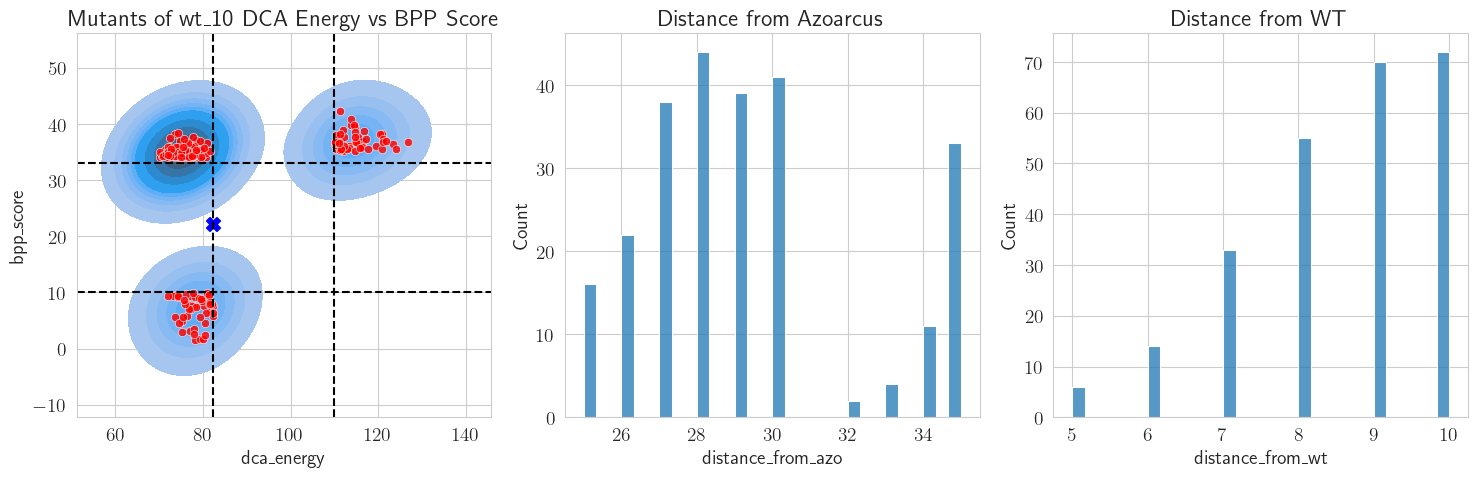

In [37]:
bpp_upper = 33
dca_min = 110
bpp_lower = 10

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

sns.kdeplot(
    data=df_results,
    x='dca_energy',
    y='bpp_score',
    fill=True,
    levels=10,
    ax=ax[0]
)
sns.scatterplot(
    data=df_results,
    x='dca_energy',
    y='bpp_score',
    color='red',
    alpha=0.8,
    ax=ax[0]
)
ax[0].scatter(wt_energy, wt_bpp_score, color='blue', s=100, label='WT', marker='X')
ax[0].axhline(bpp_upper, color='black', linestyle='--')
ax[0].axhline(bpp_lower, color='black', linestyle='--')
ax[0].axvline(dca_min, color='black', linestyle='--')
ax[0].axvline(wt_energy, color='black', linestyle='--')
ax[0].set_title(f'Mutants of {wt_name} DCA Energy vs BPP Score')


sns.histplot(
    data=df_results,
    x='distance_from_azo',
    bins=30,
    ax=ax[1]
)

sns.histplot(
    data=df_results,
    x='distance_from_wt',
    bins=30,
    ax=ax[2]
)
ax[1].set_title(f'Distance from Azoarcus')
ax[2].set_title(f'Distance from WT')
plt.tight_layout()

### Control sequences

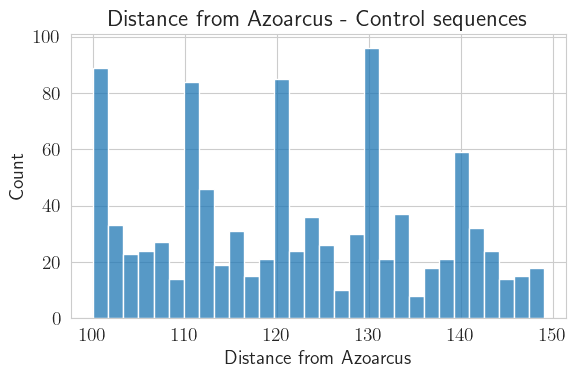

In [44]:
sequences_control_cut = [seq[3:-1] for seq in sequences_control]
sequences_control_enc = dca.encode_sequence(sequences_control_cut, tokens=tokens)
sequences_control_oh = torch.nn.functional.one_hot(torch.tensor(sequences_control_enc), num_classes=len(tokens)).float().to("cuda")

distances_from_azo_control = sequences_control_oh.shape[1] - dca.get_seqid(sequences_control_oh, s_azo_oh.squeeze(0)).cpu().numpy()

plt.figure(figsize=(6,4))
sns.histplot(
    distances_from_azo_control,
    bins=30
)
plt.title(f'Distance from Azoarcus - Control sequences')
plt.xlabel('Distance from Azoarcus')
plt.ylabel('Count')
plt.tight_layout()

In [53]:
all_headers = np.concatenate([np.array(headers_mutants), np.array(headers_control)])
all_sequences = np.concatenate([sequences_mutants, sequences_control_cut])

print(len(all_sequences))
print(len(all_headers))

3500
3500


In [54]:
fname_out = f"../Experiment_sequences/Martin_batch.fasta"
dca.write_fasta(fname_out, all_headers, all_sequences)

In [57]:
fname_final = "../Experiment_sequences/Martin_batch.fasta"
h, s = dca.import_from_fasta(fname_final, tokens=tokens)
print(len(s))

4500
